# Q9. Which brain area has the highest excitation–inhibition ratio?

**E/I can't be measured directly** from extracellular data, so I use the established LFP proxy: the **aperiodic (1/f) exponent** of the power spectrum (Gao, Peterson & Voytek, 2017).
- The LFP is the sum of excitatory and inhibitory synaptic currents. **Inhibitory currents decay more slowly**, so they put relatively more power at low frequencies.
- Their model and recordings show that more inhibition gives a **steeper** spectrum, and more excitation a **flatter** one, in the 30–50 Hz range.
- Lower exponent = flatter spectrum = **higher E/I**.

**Measure.** For each channel, a straight-line fit of log10(power) against log10(frequency) over **30–50 Hz** (the range used by Gao et al.), with the mains/equipment lines (49–51 and 52–53.5 Hz) left out.
The exponent is minus the slope. It uses the whole-recording spectra from Q2.

**The main confound and how it's checked.** Area 1 has the lowest LFP power (Q2). Broadband noise shared across channels, such as the reference or the movement/EMG transients from Q3, is flat,
so it would flatten the lowest-power area the most. The check repeats the fit on **bipolar** signals (which cancel shared noise), with a **median** over time windows (which ignores transient artifacts).

**Spike-based consistency check.** The share of each area's spikes that come from putative fast-spiking interneurons (Q7).

The code lives in `c2p/q09_ei.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, RESULTS_DIR
from c2p import q07_fs as q7
from c2p import q09_ei as q9
from c2p.stats import area_bootstrap, lmm_pairwise, per_mouse_tests

ch = q9.monopolar_table()                       # from the cached Q2 spectra
bip = q9.compute_bipolar()                      # cached; q9.compute_bipolar(force=True) recomputes (~5 min)
spectra = np.load(RESULTS_DIR / "q02_spectra.npz"); f = spectra["freqs"]
mice_ids = sorted(ch.mouse.unique())
print(f"{len(ch)} channels, {bip.groupby('band').size().iloc[0]} bipolar signals per band, {len(mice_ids)} mice")

1862 channels, 324 bipolar signals per band, 18 mice


## 1. The spectra and the fit

Each area's mean spectrum (geometric mean over mice) is shown on log–log axes, divided by its value at 30 Hz so that the **slopes** can be compared directly.
The straight lines are the 30–50 Hz fits. A flatter line means a higher E/I.

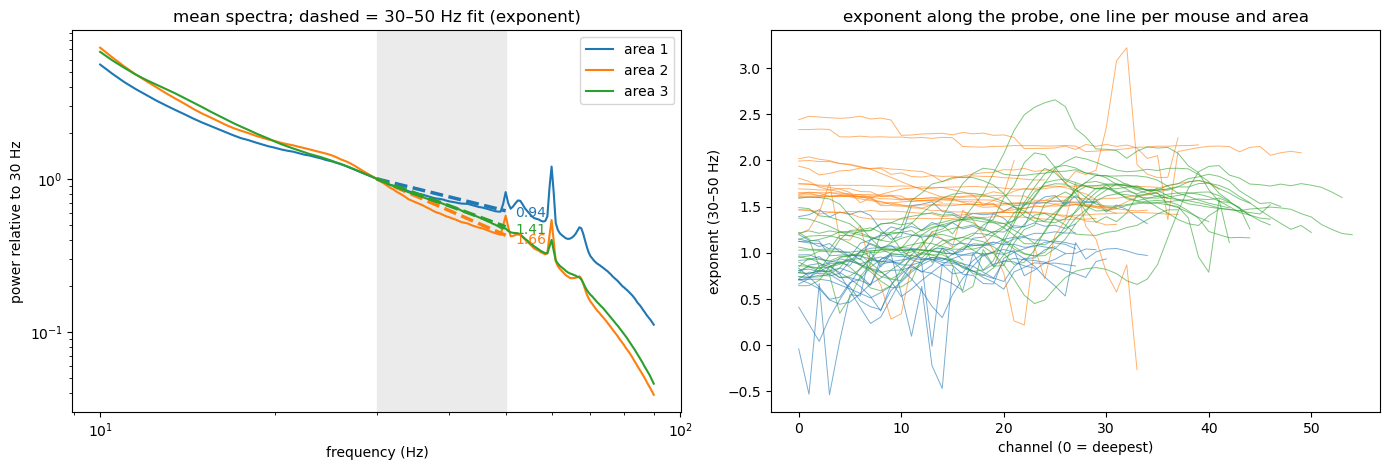

In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
sel = (f >= 10) & (f <= 90)
for a in AREAS:
    g = np.exp(np.log(np.array([spectra[f"m{m}_a{a}"].mean(0) for m in mice_ids])).mean(0))
    k = np.argmin(np.abs(f - 30))
    a1.loglog(f[sel], g[sel] / g[k], color=AREA_COLORS[a], label=f"area {a}")
    e = q9.exponent(f, g)[0]
    fx = np.linspace(30, 50, 10)
    a1.loglog(fx, (fx / 30) ** (-e) * 1.0, color=AREA_COLORS[a], ls="--", lw=2.5)
    a1.text(52, (52 / 30) ** (-e), f"{e:.2f}", color=AREA_COLORS[a], va="center")
a1.axvspan(*q9.FIT, color="0.92", zorder=0)
a1.set(xlabel="frequency (Hz)", ylabel="power relative to 30 Hz", title="mean spectra; dashed = 30–50 Hz fit (exponent)")
a1.legend()

for a in AREAS:
    for m, g in ch[ch.area == a].groupby("mouse"):
        a2.plot(g.channel, g.exponent, color=AREA_COLORS[a], lw=0.7, alpha=0.6)
a2.set(xlabel="channel (0 = deepest)", ylabel="exponent (30–50 Hz)", title="exponent along the probe, one line per mouse and area")
fig.tight_layout()

## 2. Mouse by mouse

Each line is one mouse's mean exponent over its channels, with **lower meaning higher E/I**.

Friedman p = 3.9e-08


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,0,18,7.6e-06,0.000023
area 1 vs area 3,0,18,7.6e-06,0.000023
area 2 vs area 3,17,18,5.3e-05,0.000160


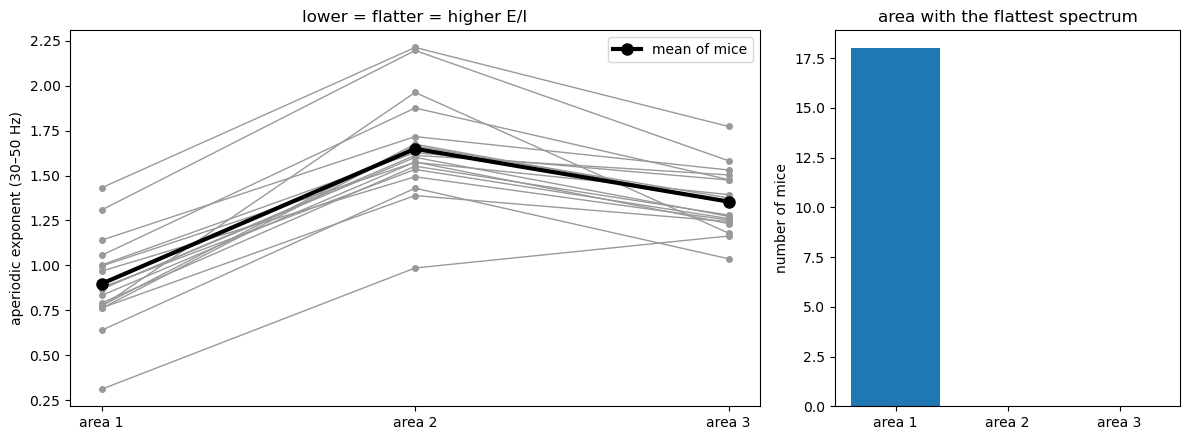

In [3]:
per_mouse, friedman, wilc = per_mouse_tests(ch, "exponent")
flattest = per_mouse.idxmin(axis=1).value_counts().reindex(AREAS, fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for m, row in per_mouse.iterrows():
    a1.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
a1.plot(AREAS, per_mouse.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
a1.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="aperiodic exponent (30–50 Hz)",
       title="lower = flatter = higher E/I"); a1.legend()
a2.bar([f"area {a}" for a in AREAS], flattest.values, color=[AREA_COLORS[a] for a in AREAS])
a2.set(ylabel="number of mice", title="area with the flattest spectrum")
fig.tight_layout()
print("Friedman p =", f"{friedman.pvalue:.1e}")
wilc.style.format({"wilcoxon p": "{:.1e}"})

## 3. Mean and 95% CI (hierarchical bootstrap over mice, then channels) and mixed model

In [4]:
t_main, boot = area_bootstrap(ch, "exponent")
display(t_main.round(3))
lmm = lmm_pairwise(ch, "exponent")
lmm.round(4)

,estimate,ci_low,ci_high,p (diff = 0)
area 1,0.930,0.817,1.047,NaN
area 2,1.672,1.521,1.821,NaN
area 3,1.356,1.277,1.441,NaN
area 1 − area 2,-0.743,-0.828,-0.660,0.0
area 1 − area 3,-0.426,-0.501,-0.356,0.0
area 2 − area 3,0.316,0.204,0.426,0.0


,coef,ci_low,ci_high,p,converged,p (Bonferroni)
contrast,,,,,,
area 1 − area 2,-0.7522,-0.8259,-0.6784,0.0,True,0.0
area 1 − area 3,-0.4577,-0.5221,-0.3933,0.0,True,0.0
area 2 − area 3,0.2944,0.1989,0.3900,0.0,True,0.0


## 4. Robustness

- **Monopolar:** other fit ranges, and the median spectrum (which ignores rare large artifacts).
- **Bipolar + median:** this cancels noise shared across channels and ignores transients. The subtraction also removes large-scale low-frequency activity, so bipolar exponents are smaller overall; only the ranking between areas is compared.

In [5]:
def summary(df):
    pm = df.groupby(["mouse", "area"]).exponent.mean().unstack()
    w = {f"{x} vs {y}": sps.wilcoxon(pm[x], pm[y]).pvalue for x, y in [(1, 2), (1, 3), (2, 3)]}
    return {**{f"area {a}": pm[a].mean() for a in AREAS},
            "flattest (mean of mice)": f"area {pm.mean().idxmin()}",
            "flattest in n mice": dict(pm.idxmin(axis=1).value_counts().sort_index()),
            "Wilcoxon p 1 vs 2": w["1 vs 2"], "Wilcoxon p 1 vs 3": w["1 vs 3"]}

rows = {"main: monopolar, mean PSD, 30–50 Hz": summary(ch),
        "monopolar, median PSD, 30–50 Hz": summary(q9.monopolar_table(which="median"))}
for band in [(20.0, 40.0), (40.0, 60.0)]:
    rows[f"monopolar, mean PSD, {band[0]:.0f}–{band[1]:.0f} Hz"] = summary(q9.monopolar_table(band=band))
for band, g in bip.groupby("band"):
    rows[f"bipolar, median PSD, {band}"] = summary(g)
robust = pd.DataFrame(rows).T
robust

,area 1,area 2,area 3,flattest (mean of mice),flattest in n mice,Wilcoxon p 1 vs 2,Wilcoxon p 1 vs 3
"main: monopolar, mean PSD, 30–50 Hz",0.897865,1.648978,1.35523,area 1,{1: 18},0.000008,0.000008
"monopolar, median PSD, 30–50 Hz",0.894086,1.585389,1.311433,area 1,{1: 18},0.000008,0.000008
"monopolar, mean PSD, 20–40 Hz",1.191904,1.815145,1.410964,area 1,{1: 18},0.000008,0.000008
"monopolar, mean PSD, 40–60 Hz",0.652041,1.377643,1.81345,area 1,{1: 18},0.000008,0.000008
"bipolar, median PSD, 20-40 Hz",0.716891,0.800197,1.082853,area 1,"{1: 11, 2: 5, 3: 2}",0.020813,0.000107
"bipolar, median PSD, 30-50 Hz",0.564628,0.733755,0.90881,area 1,"{1: 13, 2: 4, 3: 1}",0.004745,0.000038
"bipolar, median PSD, 40-60 Hz",0.385121,0.438726,1.117744,area 1,"{1: 10, 2: 8}",0.167351,0.000008


## 5. Spike-based consistency check

If area 1 has relatively less inhibition, a smaller share of its spikes should come from putative fast-spiking interneurons.
Here is the share of all spikes of an area that come from units classified as FS in Q7 (inverted waveforms excluded).
This is a different and cruder proxy: it ignores non-FS interneurons and depends on how well each cell type is sampled.

In [6]:
u = q7.compute()
u = u[~u.inverted].copy()
thr = q7.dip_threshold(u.trough_to_peak_ms)
u["fs"] = u.trough_to_peak_ms < thr
share = (u.assign(fs_rate=u.rate_hz * u.fs).groupby(["mouse", "area"])[["fs_rate", "rate_hz"]].sum()
         .eval("fs_rate / rate_hz").unstack())
print("share of spikes from FS units (mean over mice, %):", (100 * share.mean()).round(1).to_dict())
print("area with the lowest inhibitory share, per mouse:", share.idxmin(axis=1).value_counts().to_dict())
print({f"{x} vs {y}": f"{sps.wilcoxon(share[x], share[y]).pvalue:.1e}" for x, y in [(1, 2), (1, 3)]})

share of spikes from FS units (mean over mice, %): {1: 7.0, 2: 26.5, 3: 38.0}
area with the lowest inhibitory share, per mouse: {1: 16, 2: 2}
{'1 vs 2': '4.2e-04', '1 vs 3': '4.2e-04'}


## 6. Answer for the questionnaire

In [7]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

answer = t_main.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
rows_q = [(f"{r.Mean:.2f}", f"[{r['CI low']:.2f}, {r['CI high']:.2f}]", "1/f exponent") for _, r in answer.iterrows()]
answer.to_csv(RESULTS_DIR / "q09_answer.csv")
m = t_main.estimate
bip30 = robust.loc["bipolar, median PSD, 30-50 Hz"]
expl = (
    f"As a proxy for the E/I ratio I used the aperiodic exponent of the LFP spectrum (Gao et al., 2017): inhibitory "
    f"currents are slower than excitatory ones, so more inhibition steepens the spectrum, and a lower exponent indicates "
    f"higher E/I. For every channel I computed the power spectrum over the whole recording (Welch, 2-s windows) and "
    f"fitted a line to log power against log frequency over 30–50 Hz, excluding the 50 Hz mains line; the exponent is "
    f"minus the slope. Means are over channels with a hierarchical bootstrap CI (mice, then channels). Area 1 had the "
    f"flattest spectrum, i.e. the highest E/I (exponent {m['area 1']:.2f} vs {m['area 3']:.2f} in area 3 and "
    f"{m['area 2']:.2f} in area 2), in all {int(flattest[1])} of 18 mice (Friedman p < 0.001, Wilcoxon p < 0.001 "
    f"against each area, mixed model p < 0.001), and with 20–40 and 40–60 Hz fits. Because area 1 has the lowest LFP "
    f"power, shared broadband noise could flatten its spectrum; with bipolar signals and median spectra, which remove "
    f"shared noise and transients, area 1 was still the flattest ({bip30['flattest in n mice'].get(1, 0)} of 18 mice). "
    f"Consistently, area 1 also had the smallest share of spikes from putative fast-spiking interneurons."
)
expl += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
print(len(expl.split()), "words"); print(expl)
record_answer(9, choice=0, rows=rows_q, explanation=expl)     # 0 = area 1, 1 = area 2, 2 = area 3, 3 = not enough data
record_meta(9, confidence=5, consensus=4)
print(fill_pdf())

202 words
As a proxy for the E/I ratio I used the aperiodic exponent of the LFP spectrum (Gao et al., 2017): inhibitory currents are slower than excitatory ones, so more inhibition steepens the spectrum, and a lower exponent indicates higher E/I. For every channel I computed the power spectrum over the whole recording (Welch, 2-s windows) and fitted a line to log power against log frequency over 30–50 Hz, excluding the 50 Hz mains line; the exponent is minus the slope. Means are over channels with a hierarchical bootstrap CI (mice, then channels). Area 1 had the flattest spectrum, i.e. the highest E/I (exponent 0.93 vs 1.36 in area 3 and 1.67 in area 2), in all 18 of 18 mice (Friedman p < 0.001, Wilcoxon p < 0.001 against each area, mixed model p < 0.001), and with 20–40 and 40–60 Hz fits. Because area 1 has the lowest LFP power, shared broadband noise could flatten its spectrum; with bipolar signals and median spectra, which remove shared noise and transients, area 1 was still the fla

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf


## Conclusion

**Area 1 has the highest E/I ratio, judged by the 1/f-exponent proxy.** Its spectrum is the flattest in all 18 mice for every fit range.
It is still the flattest (13 of 18 mice) with bipolar, median spectra that remove shared noise, and it has the fewest spikes from putative FS interneurons.

**Confidence: moderate (5/10).**
- The exponent is an indirect proxy. Besides E/I, it also depends on the cell layout, distance from the sources and filtering.
- The margin over area 2 is smaller once shared noise is removed.
- The ranking of areas 2 and 3 flips between monopolar and bipolar signals.